In [1]:
import pandas as pd
from src.binance_data_collector import BinanceDataCollector
from src.data_preprocessor import DataPreprocessor
import plotly.graph_objects as go
import plotly.express as px
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import json

In [4]:
SYMBOLS = ['BTC-USD']
interval = '5m'
collector = BinanceDataCollector()
with open('validation/healthy_dates.json', 'r') as f:
    config_dates = json.load(f)

DATES_START_STUDY = config_dates['train']['start']
DATES_END_STUDY = config_dates['test']['end']

In [5]:
collector = BinanceDataCollector()
interval = '5m'
crypto_raw_data = collector.fetch_crypto_data(symbols = SYMBOLS, interval = interval, 
                                              start_date = DATES_START_STUDY, end_date = DATES_END_STUDY)
preprocessor = DataPreprocessor()
processed_data = preprocessor.prepare_features(crypto_raw_data, drop_bad_values = False)
processed_data = preprocessor.scale_features(processed_data.set_index(['Date', 'Symbol']), scaler = 'minmax')

INFO:root:Successfully collected data for 1 symbols
INFO:root:Total records: 105121
INFO:root:Date range: 2025-07-06 06:00:00 to 2026-07-06 06:00:00
INFO:root:Starting feature preparation...
INFO:root:Added volatility features
INFO:root:Calculating technical indicators...


Calculating volatility from OHLC data...


INFO:root:Added technical indicators
INFO:root:Using target: Volatility_20d
INFO:root:Creating lagged features...
INFO:root:Creating momentum features...
INFO:root:Creating OHLC ratios...
INFO:root:Cleaning data...
INFO:root: No rows removed, but NaN/inf values remain in the dataset
INFO:root:Feature preparation complete. Total features: 61
INFO:root:Dataset shape: (105121, 64)
INFO:root:Features: 61
INFO:root:Target: Volatility_20d


In [32]:
crypto_raw_data.columns

Index(['Date', 'Symbol', 'Open', 'High', 'Low', 'Close', 'Volume',
       'Quote_volume', 'Count', 'Taker_buy_volume', 'Taker_buy_quote_volume'],
      dtype='object')

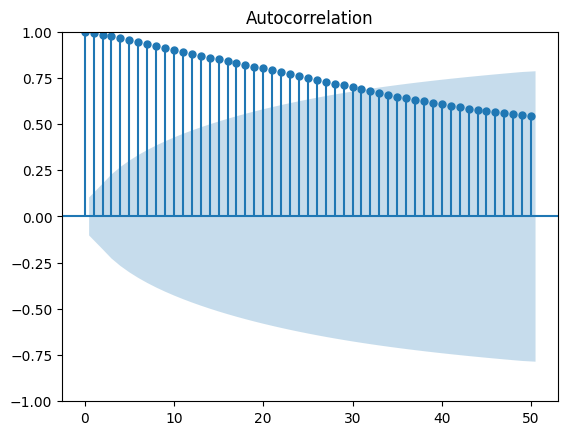

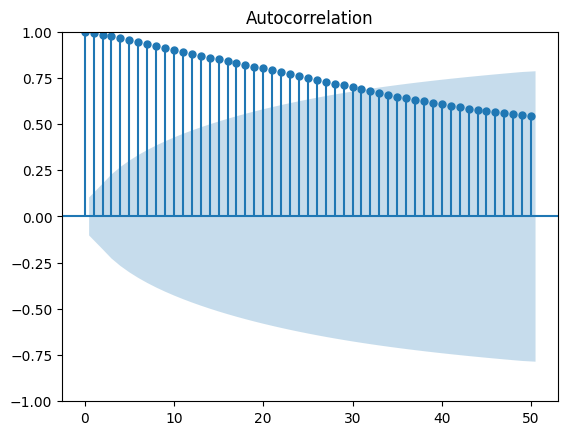

In [33]:
plot_acf(crypto_raw_data['Close'].dropna(), lags=50)

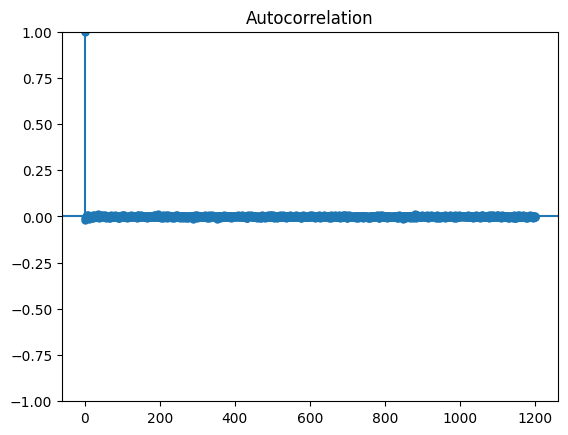

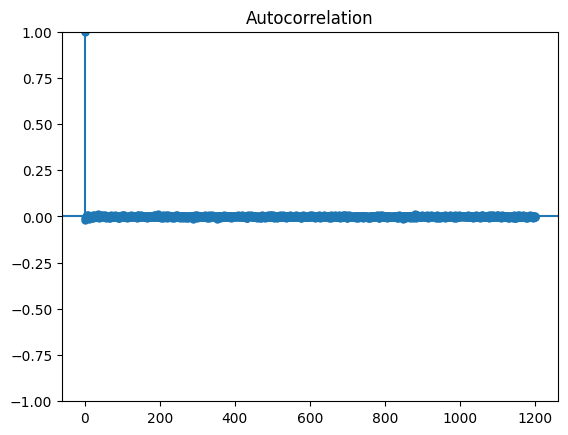

In [7]:
plot_acf(processed_data['Log_Returns'].dropna(), lags = 1200)

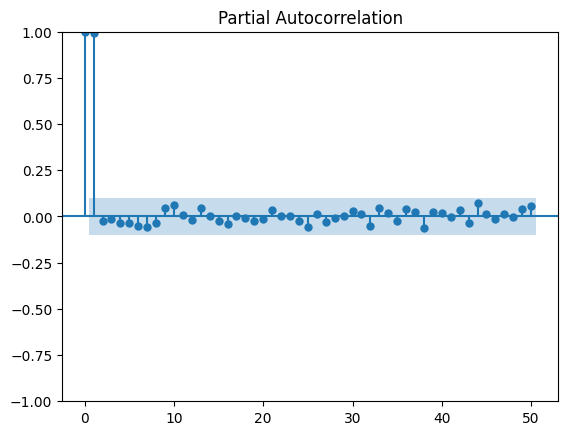

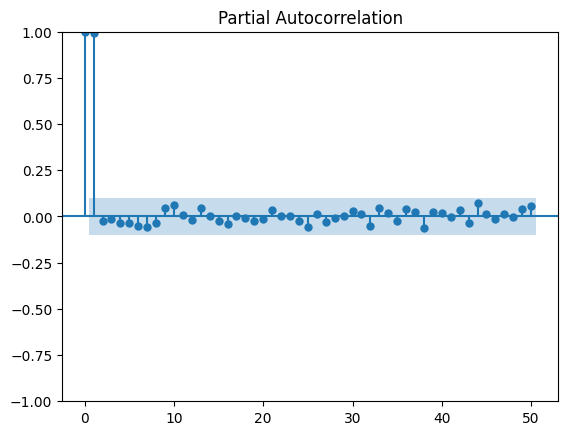

In [35]:
plot_pacf(crypto_raw_data['Close'].dropna(), lags=50)

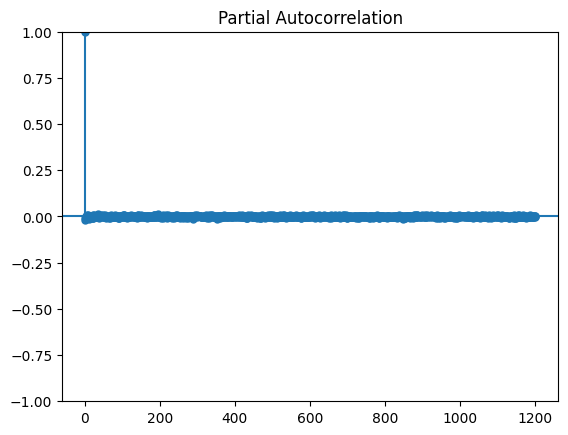

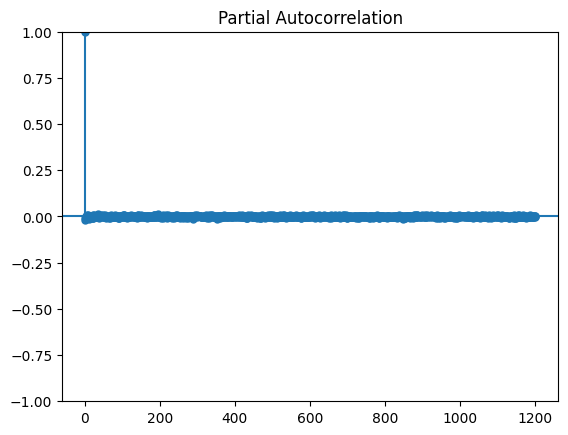

In [8]:
plot_pacf(processed_data['Log_Returns'].dropna(), lags=1200)

In [9]:
px.line(processed_data.reset_index().iloc[0:15000], y = 'Log_Returns', 
        x = 'Date',
        title = 'Log Returns of BTC-USD', labels = {'Log_Returns': 'Log Returns', 'Date': 'Date'})

In [38]:
px.line(processed_data.reset_index().iloc[0:1500], y = 'Volume', 
        x = 'Date',
        title = 'Volume of BTC-USD', labels = {'Volume': 'Volume', 'Date': 'Date'})

In [39]:
px.line(processed_data.reset_index().iloc[0:1500], y = 'Count', 
        x = 'Date',
        title = 'Count of BTC-USD', labels = {'Count': 'Count', 'Date': 'Date'})

In [40]:
processed_data[['Returns', 'Volume','Count']]

,,Returns,Volume,Count
Date,Symbol,,,
2025-07-07,BTC-USD,NaN,0.061062,0.083529
2025-07-08,BTC-USD,0.558071,0.059227,0.067206
2025-07-09,BTC-USD,0.615759,0.137392,0.108594
2025-07-10,BTC-USD,0.698627,0.211051,0.170038
2025-07-11,BTC-USD,0.584723,0.220645,0.202943
...,...,...,...,...
2026-07-02,BTC-USD,0.632443,0.177122,0.214903
2026-07-03,BTC-USD,0.598229,0.106060,0.125214
2026-07-04,BTC-USD,0.568996,0.058489,0.061739


In [ ]:
processed_data

Date                 Symbol 
2025-07-06 06:00:00  BTC-USD    0.004828
2025-07-06 07:00:00  BTC-USD    0.004099
2025-07-06 08:00:00  BTC-USD    0.008395
2025-07-06 09:00:00  BTC-USD    0.006636
2025-07-06 10:00:00  BTC-USD    0.007514
                                  ...   
2026-07-06 02:00:00  BTC-USD    0.015362
2026-07-06 03:00:00  BTC-USD    0.016362
2026-07-06 04:00:00  BTC-USD    0.010146
2026-07-06 05:00:00  BTC-USD    0.028677
2026-07-06 06:00:00  BTC-USD    0.025169
Name: Volume, Length: 8761, dtype: float64

In [ ]:
processed_data['Volume'].describe()

In [26]:
processed_data[['Returns', 'Log_Returns']]

,,Returns,Log_Returns
Date,Symbol,,
2025-07-06 06:00:00,BTC-USD,NaN,NaN
2025-07-06 07:00:00,BTC-USD,0.572275,0.582459
2025-07-06 08:00:00,BTC-USD,0.577471,0.587620
2025-07-06 09:00:00,BTC-USD,0.564052,0.574288
2025-07-06 10:00:00,BTC-USD,0.597131,0.607126
...,...,...,...
2026-07-06 02:00:00,BTC-USD,0.559388,0.569650
2026-07-06 03:00:00,BTC-USD,0.549847,0.560158
2026-07-06 04:00:00,BTC-USD,0.576427,0.586583
